# Notebook 2 — Anatomy of a Demonstration

### Course roadmap

**Part I — the data**
1. What Physical AI is & what an action really is · **2. Anatomy of a demonstration**

**Part II — simulation from first principles** (`numpy` only)
3. Physics from scratch · 4. The robot model · 5. Control before learning

**Part III — learning policies** (`pytorch`)
6. Behavior cloning · 7. Action chunking & diffusion policies · 8. RL in simulation (SAC)

**Part IV — reality and production**
9. Sim-to-real · 10. `lerobot` end to end

---

### What this notebook does

Notebook 1 answered *what an action is*. This one answers a harder and more
practical question: **is this data any good, and what will a policy trained on
it actually learn?**

In imitation learning your policy is a function of your demonstrations. There is
no reward to rescue you from bad data — whatever is in the dataset is what the
policy copies, inconsistencies included. So the skill of *interrogating a
dataset before training on it* is not optional housekeeping. It is the highest-
leverage hour you will spend.

Everything here is `pandas` and `numpy`. By the end you will have:

- velocities, accelerations, and a smoothness measure for every episode
- the phase structure of the task extracted automatically
- a measurement of **where demonstrations disagree with each other**, which
  predicts exactly where a cloned policy will hesitate
- **normalisation statistics** saved to disk — the artifact notebook 6 trains with
- a reusable 10-minute checklist for judging any robot dataset on HuggingFace

## 1. Reload, and build a tidy frame

Notebook 1 left the data in LeRobot's native layout: array-valued object columns.
That is fine for storage and wrong for analysis. The first move is always to
explode those into one column per joint, which gives us a genuinely tabular
frame that `pandas` can group, aggregate and correlate.

This is worth doing carefully once, because every later notebook reuses it.

In [11]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

REPO, FPS = "lerobot/svla_so101_pickplace", 30
JOINTS = ["shoulder_pan", "shoulder_lift", "elbow_flex", "wrist_flex", "wrist_roll", "gripper"]

raw = pd.read_parquet(hf_hub_download(REPO, "data/chunk-000/file-000.parquet", repo_type="dataset"))

# Explode the two array columns into one float column per joint.
# `np.stack` turns an object column of 6-arrays into a clean (N, 6) float matrix.
S = np.stack(raw["observation.state"].values).astype(np.float64)
A = np.stack(raw["action"].values).astype(np.float64)

df = pd.DataFrame({"episode": raw["episode_index"].values,
                   "frame":   raw["frame_index"].values,
                   "t":       raw["timestamp"].values.astype(np.float64)})
for i, j in enumerate(JOINTS):
    df[f"state_{j}"]  = S[:, i]
    df[f"action_{j}"] = A[:, i]

df = df.sort_values(["episode", "frame"]).reset_index(drop=True)
print(f"tidy frame: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"columns: {list(df.columns)}\n")
print(df.head(3).to_string())

tidy frame: 11939 rows x 15 columns
columns: ['episode', 'frame', 't', 'state_shoulder_pan', 'action_shoulder_pan', 'state_shoulder_lift', 'action_shoulder_lift', 'state_elbow_flex', 'action_elbow_flex', 'state_wrist_flex', 'action_wrist_flex', 'state_wrist_roll', 'action_wrist_roll', 'state_gripper', 'action_gripper']

   episode  frame         t  state_shoulder_pan  action_shoulder_pan  state_shoulder_lift  action_shoulder_lift  state_elbow_flex  action_elbow_flex  state_wrist_flex  action_wrist_flex  state_wrist_roll  action_wrist_roll  state_gripper  action_gripper
0        0      0  0.000000            1.956088             1.911765           -98.743721             -99.41053         98.924248           99.54483         74.819839           74.84063        -51.452991         -48.522587       1.409396        1.622875
1        0      1  0.033333            1.956088             1.911765           -98.743721             -99.41053         98.924248           99.54483         74.819839    

Now `describe()` is actually meaningful, which it was not before. This is the
first thing to look at in any new dataset.

In [12]:
state_cols = [f"state_{j}" for j in JOINTS]
desc = df[state_cols].describe().T[["min", "25%", "50%", "75%", "max", "std"]]
desc.index = JOINTS
print("joint position distributions across all 50 episodes:\n")
print(desc.round(2).to_string())
print()
print("Note the units: these are NOT radians or degrees. They are normalised")
print("servo positions, roughly -100..100. Every joint has a different range and")
print("a different centre -- which is exactly why normalisation (section 6) matters.")

joint position distributions across all 50 episodes:

                 min    25%    50%    75%    max    std
shoulder_pan  -92.65  -8.10   4.91  42.91  88.10  44.49
shoulder_lift -98.91 -98.49 -45.06 -23.03   8.79  36.83
elbow_flex     16.81  40.21  59.57  98.92  99.37  27.71
wrist_flex     34.04  59.73  73.12  74.65  98.64  13.01
wrist_roll    -92.28 -60.93 -53.94 -40.71 -20.20  17.70
gripper         1.21   1.48   6.85  12.28  32.68   8.41

Note the units: these are NOT radians or degrees. They are normalised
servo positions, roughly -100..100. Every joint has a different range and
a different centre -- which is exactly why normalisation (section 6) matters.


Read the `std` column. `shoulder_pan` varies by ~25 units across the dataset
while `wrist_roll` varies by ~6. If you fed these raw into a neural network, the
loss would be dominated by whichever joint happens to have the largest numerical
range — and that joint is not necessarily the one that matters for the task.
That is the whole argument for normalisation, and we will come back to it.

Also note: **these are not degrees or radians.** They are normalised servo
units. A common beginner error is to assume robot joint data is in SI units and
then wonder why a "0.1 radian" correction does nothing.

## 2. Velocity: the derivative you have to compute yourself

The dataset gives positions, not velocities. But velocity is where the
interesting physics lives — it tells you how fast the human was moving the arm,
where they slowed down to be careful, and whether the data is smooth enough to
imitate.

Since positions are sampled at a fixed 30 fps, the finite difference is just

$$
v_t \approx \frac{s_{t+1} - s_t}{\Delta t}, \qquad \Delta t = \frac{1}{30}\,\text{s}
$$

One subtlety that bites people: **you must difference within an episode, never
across the boundary between two episodes.** Episode 0 ends with the arm
somewhere and episode 1 starts from the home position, so a naive global
`np.diff` invents a gigantic fictitious velocity at every boundary. `groupby`
handles this correctly.

In [13]:
# Differencing inside each episode -- groupby prevents the cross-episode artefact.
for j in JOINTS:
    df[f"vel_{j}"] = df.groupby("episode")[f"state_{j}"].diff() * FPS       # units / second
    df[f"acc_{j}"] = df.groupby("episode")[f"vel_{j}"].diff() * FPS         # units / second^2

vel_cols = [f"vel_{j}" for j in JOINTS]

# Demonstrate why groupby matters: compare against the naive global diff.
naive = np.diff(df["state_shoulder_pan"].values, prepend=np.nan) * FPS
boundaries = df.index[df["frame"] == 0][1:]              # first frame of each episode after the 0th
grp = df["vel_shoulder_pan"].values[boundaries]
print("|velocity| at episode boundaries, shoulder_pan:")
print(f"  naive global diff : max {np.nanmax(np.abs(naive[boundaries])):6.1f} units/s  <- fictitious jump")
print(f"  groupby diff      : {'all NaN' if np.all(np.isnan(grp)) else f'max {np.nanmax(np.abs(grp)):.1f}'}"
      f"              <- correctly undefined")
print()

print("speed per joint (absolute velocity, units/s):\n")
out = pd.DataFrame({
    "median |v|": df[vel_cols].abs().median().values,
    "p95 |v|":    df[vel_cols].abs().quantile(0.95).values,
    "max |v|":    df[vel_cols].abs().max().values,
    "frac exactly 0": (df[vel_cols].abs() < 1e-9).mean().values,
}, index=JOINTS)
print(out.round(3).to_string())

|velocity| at episode boundaries, shoulder_pan:
  naive global diff : max   52.7 units/s  <- fictitious jump
  groupby diff      : all NaN              <- correctly undefined

speed per joint (absolute velocity, units/s):

               median |v|  p95 |v|  max |v|  frac exactly 0
shoulder_pan        7.186  124.551  217.964           0.345
shoulder_lift       0.000  125.628  266.332           0.544
elbow_flex          0.000   96.817  182.878           0.645
wrist_flex          0.000   78.847  175.498           0.564
wrist_roll          0.000   55.678  106.960           0.539
gripper             0.000   56.376  213.423           0.829


Two things to read off this table, and the second one is a trap.

**The spread is enormous.** The p95 speed is 10-20x the median for every joint:
the arm spends most of its time barely moving and occasionally makes a fast
transit. That is characteristic of teleoperated manipulation — careful near the
object, quick through free space.

**The median is 0.00 for five of six joints, and `frac exactly 0` explains why.**
A large share of consecutive frames have *bit-identical* joint readings. This is
not stillness, it is **encoder quantisation**: the servo reports position at
finite resolution, so slow motion registers as a sequence of zero-changes
punctuated by single-step jumps. Median velocity is therefore the wrong summary
statistic for this data — use a high percentile instead.

This matters practically. If you compute "is the robot moving" with a small
velocity threshold, quantisation will tell you it is stationary a third of the
time while it is in fact drifting slowly. Later we use a percentile-relative
threshold for exactly this reason.

Now the connection back to notebook 1's lag.

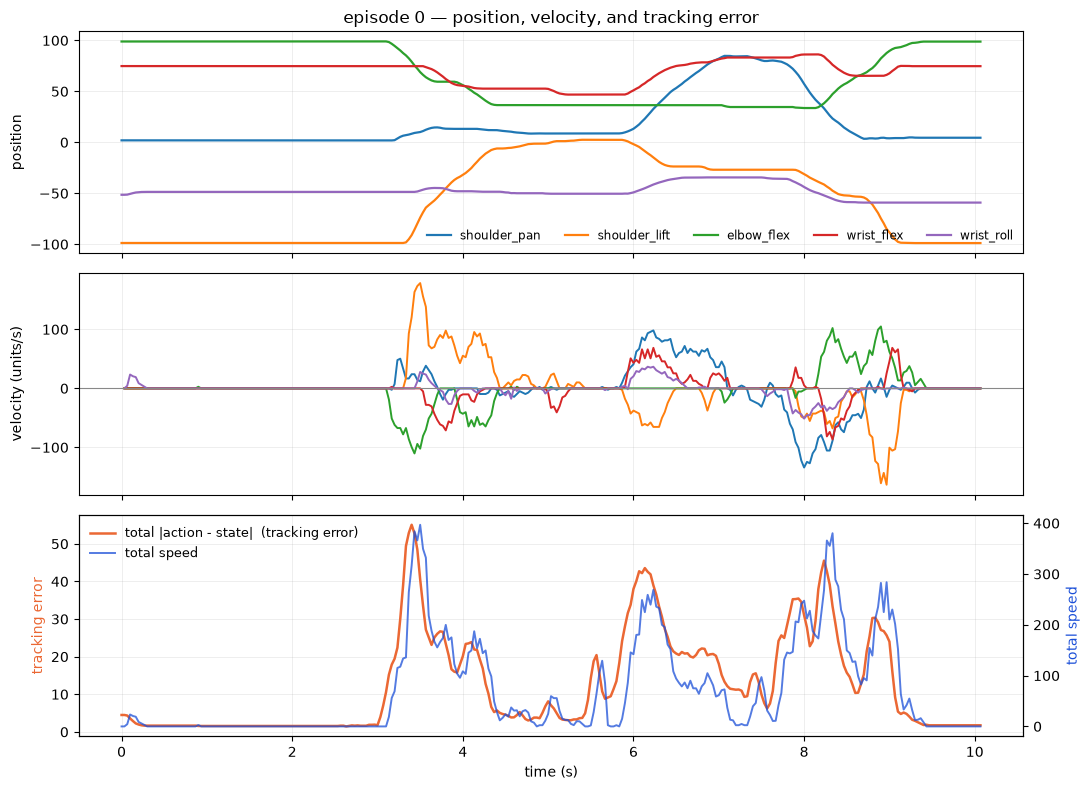

corr(tracking error, speed) = 0.865


In [14]:
ep = df[df.episode == 0]
t = ep["t"].values

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)

ax = axes[0]
for j in JOINTS:
    if j != "gripper":
        ax.plot(t, ep[f"state_{j}"], lw=1.6, label=j)
ax.set_ylabel("position"); ax.set_title("episode 0 — position, velocity, and tracking error", fontsize=12)
ax.legend(frameon=False, ncol=5, fontsize=8.5); ax.grid(alpha=0.25, lw=0.6)

ax = axes[1]
for j in JOINTS:
    if j != "gripper":
        ax.plot(t, ep[f"vel_{j}"], lw=1.4, label=j)
ax.axhline(0, color="#888", lw=0.8)
ax.set_ylabel("velocity (units/s)"); ax.grid(alpha=0.25, lw=0.6)

# Tracking error: how far behind the target is the arm? This IS the lag from nb1.
ax = axes[2]
err = np.zeros(len(ep))
for j in JOINTS:
    err += np.abs(ep[f"action_{j}"].values - ep[f"state_{j}"].values)
speed = ep[vel_cols].abs().sum(axis=1).values
ax.plot(t, err, lw=1.8, color="#eb6834", label="total |action - state|  (tracking error)")
ax2 = ax.twinx()
ax2.plot(t, speed, lw=1.4, color="#1b4fd8", alpha=0.75, label="total speed")
ax.set_xlabel("time (s)"); ax.set_ylabel("tracking error", color="#eb6834")
ax2.set_ylabel("total speed", color="#1b4fd8")
ax.grid(alpha=0.25, lw=0.6)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.show()

r = np.corrcoef(err[1:], speed[1:])[0, 1]
print(f"corr(tracking error, speed) = {r:.3f}")

That correlation is the mechanical explanation of notebook 1's lag, and it is
worth stating as a principle:

> **The arm falls behind its target in proportion to how fast it is being asked
> to move.** When the human moves slowly, the arm keeps up and the tracking
> error is near zero. During a fast transit, the error spikes.

So the 133 ms lag is not a fixed delay bolted onto the system — it is the
*consequence* of a position controller with finite authority chasing a moving
setpoint. A constant-delay model would be a simplification. We will build the
real thing in notebook 5, where this becomes a P-controller with a gain you can
set, and you will watch this exact curve emerge from the dynamics.

## 3. Phase structure, extracted automatically

Notebook 1 showed the gripper segments the task. Let us make that rigorous and
apply it to all 50 episodes, because the phase boundaries are where the
interesting variation lives.

In [15]:
g = df["state_gripper"]
lo, hi = g.quantile(0.05), g.quantile(0.95)
thresh = (lo + hi) / 2
print(f"gripper: 5th pct {lo:.2f}, 95th pct {hi:.2f}  ->  open/closed threshold {thresh:.2f}\n")

def phases(ep_df):
    """Return (grasp_frame, release_frame) using the first close and the following open."""
    closed = (ep_df["state_gripper"].values < thresh).astype(int)
    switches = np.where(np.diff(closed) != 0)[0]
    grasp = release = np.nan
    for s in switches:
        if closed[s + 1] == 1 and np.isnan(grasp):
            grasp = s + 1
        elif closed[s + 1] == 0 and not np.isnan(grasp):
            release = s + 1
            break
    return grasp, release

rows = []
for e, ep_df in df.groupby("episode"):
    gr, rl = phases(ep_df)
    rows.append({"episode": e, "length": len(ep_df), "grasp": gr, "release": rl})
ph = pd.DataFrame(rows)
ph["grasp_s"]   = ph["grasp"] / FPS
ph["release_s"] = ph["release"] / FPS
ph["carry_s"]   = (ph["release"] - ph["grasp"]) / FPS

print(f"detected a grasp in {ph['grasp'].notna().sum()}/{len(ph)} episodes, "
      f"a release in {ph['release'].notna().sum()}/{len(ph)}\n")
print(ph[["length", "grasp_s", "release_s", "carry_s"]].describe().round(2).T.to_string())

gripper: 5th pct 1.28, 95th pct 24.16  ->  open/closed threshold 12.72

detected a grasp in 50/50 episodes, a release in 26/50

           count    mean    std     min     25%     50%     75%     max
length      50.0  238.78  30.80  183.00  215.25  230.50  261.75  306.00
grasp_s     50.0    3.64   0.75    2.27    3.13    3.55    4.12    5.63
release_s   26.0    5.68   0.96    4.40    4.74    5.75    6.40    7.53
carry_s     26.0    1.96   0.40    1.13    1.76    1.97    2.25    2.73


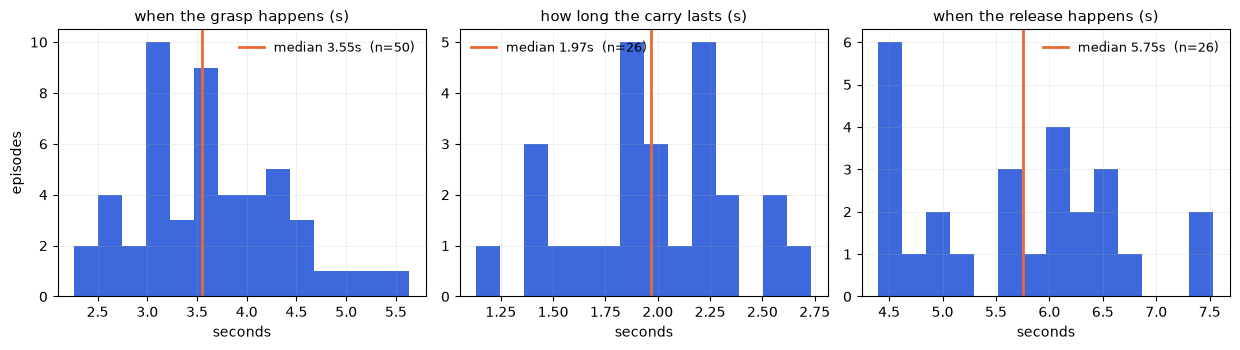

grasp detected in 50/50 episodes, release in only 26/50.

That asymmetry is a real finding about this dataset, not a bug in the detector:
in roughly half the episodes the recording stops while the gripper is still
closed -- the operator ended the take before (or during) the release.

Grasp timing spread: 2.3s to 5.6s (median 3.5s).
A policy that sees only the current observation cannot know how far through
the task it is, so at a given arm pose the demonstrations disagree about
whether to keep reaching or to close the gripper. Section 4 measures that.


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, col, title in zip(axes,
                          ["grasp_s", "carry_s", "release_s"],
                          ["when the grasp happens (s)", "how long the carry lasts (s)", "when the release happens (s)"]):
    v = ph[col].dropna()
    ax.hist(v, bins=14, color="#1b4fd8", alpha=0.85)
    ax.axvline(v.median(), color="#eb6834", lw=2, label=f"median {v.median():.2f}s  (n={len(v)})")
    ax.set_title(title, fontsize=10.5); ax.set_xlabel("seconds")
    ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.22, lw=0.6)
axes[0].set_ylabel("episodes")
plt.tight_layout(); plt.show()

n_rel = int(ph["release"].notna().sum())
print(f"grasp detected in {int(ph['grasp'].notna().sum())}/50 episodes, release in only {n_rel}/50.")
print()
print("That asymmetry is a real finding about this dataset, not a bug in the detector:")
print("in roughly half the episodes the recording stops while the gripper is still")
print("closed -- the operator ended the take before (or during) the release.")
print()
print(f"Grasp timing spread: {ph['grasp_s'].min():.1f}s to {ph['grasp_s'].max():.1f}s "
      f"(median {ph['grasp_s'].median():.1f}s).")
print("A policy that sees only the current observation cannot know how far through")
print("the task it is, so at a given arm pose the demonstrations disagree about")
print("whether to keep reaching or to close the gripper. Section 4 measures that.")

Worth pausing on the 26/50. Half these demonstrations never show a completed
release — the episode ends mid-carry.

For imitation learning that is a genuine data problem, not a curiosity. A policy
trained on this set sees plenty of evidence for "reach and grasp" and only half
as much for "release and retreat", so it will be systematically weaker at
finishing the task than at starting it. If you were collecting this data
yourself, the fix is a recording protocol that runs a second past the release.

This is the kind of thing you only find by looking. The dataset card does not
mention it.

## 4. Do the demonstrations disagree with each other?

This is the most important section in the notebook, and the one where we have to
be most careful not to fool ourselves.

A behavior-cloning policy learns $\pi(a \mid o)$ by regression. If two
demonstrations show the arm in *the same place* but the human did *different
things*, a mean-squared-error loss cannot satisfy both — it outputs the
**average** of the two actions, which is frequently a third action that
accomplishes nothing. The classic symptom: the arm drifts to a point halfway
between "reach further" and "close the gripper" and stalls.

This is **multimodality in the demonstration data**, and it is the usual
explanation for why naive BC fails. It is also the motivation for diffusion
policies in notebook 7, which model the full action distribution instead of its
mean.

So: **is this dataset multimodal?** People assert this about robot data
routinely. Let us actually measure it, because the answer determines whether
notebook 6's simple policy has a chance.

The method needs a **baseline**, and choosing it well is the whole game. We will
compare:

- **signal** — at near-identical arm poses in *different* episodes, how far apart are the recorded actions?
- **baseline** — how much does the action change between *consecutive frames* (33 ms)? That is the smallest action difference that means anything physically.

If the signal stays well above the baseline even as poses become identical, the
data is multimodal. If it decays to the baseline, it is not.

In [17]:
# signal vs baseline, with the decay curve that actually settles the question.
rng = np.random.default_rng(0)
Sall = df[state_cols].values
Aall = df[[f"action_{j}" for j in JOINTS]].values
eps  = df["episode"].values
prog_all = df["frame"].values / df.groupby("episode")["frame"].transform("max").values

scale = Sall.std(axis=0)          # per-joint std, so "close in state" weights joints evenly
Z = Sall / scale

# baseline: consecutive-frame action change, within episodes
consec = []
for e, ed in df.groupby("episode"):
    Ae = ed[[f"action_{j}" for j in JOINTS]].values / scale
    consec.append(np.linalg.norm(np.diff(Ae, axis=0), axis=1))
baseline = float(np.median(np.concatenate(consec)))

idx = rng.choice(len(df), size=2500, replace=False)
d_state, d_action, d_prog = [], [], []
for i_ in idx:
    d = np.linalg.norm(Z - Z[i_], axis=1)
    d[eps == eps[i_]] = np.inf                  # force the match into a different episode
    nn = int(np.argmin(d))
    if not np.isfinite(d[nn]):
        continue
    d_state.append(d[nn])
    d_action.append(np.linalg.norm((Aall[nn] - Aall[i_]) / scale))
    d_prog.append(abs(prog_all[nn] - prog_all[i_]))

d_state, d_action, d_prog = np.array(d_state), np.array(d_action), np.array(d_prog)

tight = d_state <= np.quantile(d_state, 0.10)   # <= matters: many distances tie at the low end
print(f"{len(d_action)} frames matched to their nearest state in another episode\n")
print(f"baseline — median |action[t+1] - action[t]|, 33 ms apart     : {baseline:.3f}")
print(f"signal   — median action gap over ALL matches                : {np.median(d_action):.3f}   "
      f"({np.median(d_action)/baseline:.1f}x baseline)")
print(f"signal   — restricted to the closest 10% of matches          : {np.median(d_action[tight]):.3f}   "
      f"({np.median(d_action[tight])/baseline:.1f}x baseline)")
print(f"           (median state distance in that group: {np.median(d_state[tight]):.3f})")

2500 frames matched to their nearest state in another episode

baseline — median |action[t+1] - action[t]|, 33 ms apart     : 0.070
signal   — median action gap over ALL matches                : 0.297   (4.3x baseline)
signal   — restricted to the closest 10% of matches          : 0.014   (0.2x baseline)
           (median state distance in that group: 0.000)


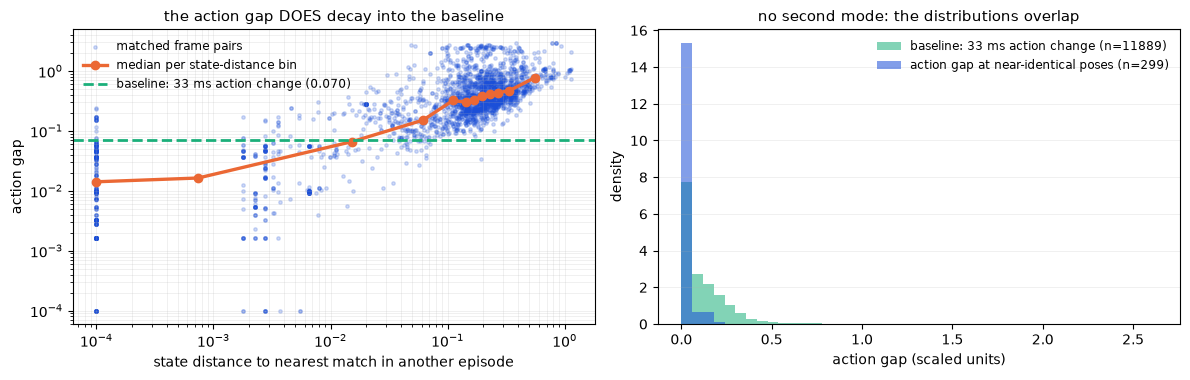

closest bin  : state dist 0.0001 -> action gap 0.014  (0.20x baseline)
farthest bin : state dist 0.5535 -> action gap 0.773  (11.06x baseline)

at near-identical poses, 0.0% of action gaps exceed the baseline's 95th percentile.
A genuinely multimodal dataset would put a large fraction out there. This one does not.


In [18]:
# The decay curve is the answer. Bin by state distance and track the action gap.
nb_bins = 12
edges = np.quantile(d_state, np.linspace(0, 1, nb_bins + 1))
centres, med_gap = [], []
for b in range(nb_bins):
    m = (d_state >= edges[b]) & (d_state <= edges[b + 1])
    if m.sum() > 15:
        centres.append(max(d_state[m].mean(), 1e-4)); med_gap.append(np.median(d_action[m]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))

ax = axes[0]
ax.scatter(np.maximum(d_state, 1e-4), np.maximum(d_action, 1e-4), s=6, alpha=0.2,
           color="#1b4fd8", label="matched frame pairs")
ax.plot(centres, med_gap, lw=2.4, marker="o", color="#eb6834", label="median per state-distance bin")
ax.axhline(baseline, color="#1baf7a", lw=2, ls="--", label=f"baseline: 33 ms action change ({baseline:.3f})")
ax.set_xlabel("state distance to nearest match in another episode")
ax.set_ylabel("action gap"); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("the action gap DOES decay into the baseline", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5); ax.grid(alpha=0.22, lw=0.6, which="both")

# Right panel: the distributions. Multimodal data would show a second hump
# well to the right of the baseline distribution. Unimodal data overlaps it.
ax = axes[1]
base_all = np.concatenate(consec)
bins = np.linspace(0, np.quantile(base_all, 0.995) * 3, 45)
ax.hist(base_all, bins=bins, density=True, alpha=0.55, color="#1baf7a",
        label=f"baseline: 33 ms action change (n={len(base_all)})")
ax.hist(d_action[tight], bins=bins, density=True, alpha=0.55, color="#1b4fd8",
        label=f"action gap at near-identical poses (n={tight.sum()})")
ax.set_xlabel("action gap (scaled units)"); ax.set_ylabel("density")
ax.set_title("no second mode: the distributions overlap", fontsize=10.5)
ax.legend(frameon=False, fontsize=8.5); ax.grid(alpha=0.22, lw=0.6, axis="y")
plt.tight_layout(); plt.show()

print(f"closest bin  : state dist {centres[0]:.4f} -> action gap {med_gap[0]:.3f}  ({med_gap[0]/baseline:.2f}x baseline)")
print(f"farthest bin : state dist {centres[-1]:.4f} -> action gap {med_gap[-1]:.3f}  ({med_gap[-1]/baseline:.2f}x baseline)")
print()
frac_above = float((d_action[tight] > np.quantile(base_all, 0.95)).mean())
print(f"at near-identical poses, {100*frac_above:.1f}% of action gaps exceed the baseline's 95th percentile.")
print("A genuinely multimodal dataset would put a large fraction out there. This one does not.")

### Reading this honestly: the answer is no

I expected this dataset to be strongly multimodal. **It is not**, and the
measurement says so clearly.

The left panel is the result. On log axes, the action gap **falls steadily as
the state distance shrinks**, and in the closest bin it drops *below* the 33 ms
baseline. Read plainly: when two episodes put the arm in genuinely the same
pose, the human commanded genuinely the same action. The elevated median over
*all* matches (~4x baseline) is not disagreement — it is just that most
"nearest" matches are not actually that near, and the action gap tracks the
state gap.

The right panel makes the same point distributionally. If the data were
multimodal, the blue histogram would have a second hump far to the right of the
green one — pairs of near-identical poses with wildly different actions. It does
not; the two distributions sit on top of each other.

(I first tried to test this by splitting close-pose matches on task-phase
mismatch. That measurement is **confounded** and I removed it: among
close-state matches, the different-phase pairs are overwhelmingly the arm
sitting near its home position at the start and end of episodes, where the
commanded action is near zero regardless of phase. It produced a backwards
result for a reason that had nothing to do with multimodality. Exercise 1 does
it properly, by conditioning on phase as an *input* rather than slicing on it.)

**What this means for the rest of the course.** This dataset is *stereotyped*:
50 takes of the same motion, by the same operator, with the object in nearly the
same place. That is consistent with section 5's finding that the episodes are
uniformly clean (jerk spread under 2x). So:

- **Notebook 6's plain behavior-cloning policy should work reasonably here.** We
  predicted it would stall from mode-averaging; the data says that specific
  failure is unlikely on this dataset.
- The failure we *should* still expect is **compounding error** — the exposure
  bias you measured in notebook 13 of the RL course — because that is a property
  of the horizon, not the data's modality. 230 steps is a long way to drift.
- **Diffusion policies (notebook 7) will therefore not look dramatically better
  than BC on this dataset.** To see them earn their complexity you need data
  that *is* multimodal: multiple operators, varied object placement, or several
  valid strategies per task. Exercise 4 points you at one.

This is the honest reason to run the measurement rather than cite the folklore.
"Robot data is multimodal" is true of many datasets and false of this one, and
the difference changes which method you should reach for. Had I trusted the
received wisdom, I would have told you to skip BC and go straight to diffusion —
and on this data that would have been wrong.

### How to read a dataset for multimodality, in general

The procedure, independent of this dataset:

1. Pick a **baseline** for "actions that are meaningfully different". The
   consecutive-frame action change is a good, assumption-free choice.
2. Match frames across episodes by state, scaled per-dimension so no single
   joint dominates the distance.
3. **Plot the action gap against the state distance, on log axes.** Multimodal
   data plateaus above the baseline as the state distance goes to zero.
   Unimodal data decays into it, as here.
4. If there is a plateau, condition on what you think explains it — phase,
   object position, operator identity — and see whether the plateau collapses.
   Whatever makes it collapse is the missing input to your policy.

Step 3 is the one worth remembering. A single number — "median action gap" —
would have told you this dataset is 4x the baseline and sent you chasing a
problem it does not have. The *decay curve* is what answers the question.

## 5. Judging episode quality

Not all 50 demonstrations are equally good. Human teleoperation produces
hesitations, corrections, and the occasional fumble. Training on a bad
demonstration teaches the policy to fumble, so it is worth being able to rank them.

Three cheap, interpretable signals:

- **Jerk** — the third derivative of position. High jerk means a jittery,
  hesitant demonstration rather than a confident motion.
- **Path inefficiency** — total distance travelled divided by net displacement.
  A value near 1 is a direct move; a large value means wandering or correcting.
- **Idle fraction** — the share of frames with almost no movement. Lots of idle
  time means the operator was thinking, and the policy will learn to pause.

In [19]:
# Three interpretable quality signals. Note the choice of a BOUNDED path measure:
# total_path / net_displacement explodes when an episode returns near its start
# (net ~ 0), which made early versions of this metric unreadable. Path length
# per second is bounded, comparable across episodes, and means something.
rows = []
for e, ep_df in df.groupby("episode"):
    A3 = ep_df[[f"acc_{j}" for j in JOINTS]].values[2:]
    P = ep_df[state_cols].values / scale
    step = np.linalg.norm(np.diff(P, axis=0), axis=1)
    sp = np.linalg.norm(ep_df[vel_cols].values[1:] / scale, axis=1)
    thr = np.quantile(sp, 0.90) * 0.05                      # percentile-relative (quantisation-safe)
    rows.append({
        "episode": e,
        "length_s": len(ep_df) / FPS,
        "jerk": np.abs(np.diff(A3, axis=0)).mean() if len(A3) > 1 else np.nan,
        "path_per_s": step.sum() / (len(ep_df) / FPS),      # scaled units travelled per second
        "reversals": int((np.diff(np.sign(np.diff(P[:, 0]))) != 0).sum()),  # direction changes, shoulder_pan
        "idle_frac": float((sp < thr).mean()),
    })
q = pd.DataFrame(rows).set_index("episode")

print("episode quality metrics:\n")
print(q.describe().round(2).T.to_string())
print("\n--- 5 smoothest (lowest jerk) ---")
print(q.nsmallest(5, "jerk").round(2).to_string())
print("\n--- 5 jerkiest: inspect these before training on them ---")
print(q.nlargest(5, "jerk").round(2).to_string())

episode quality metrics:

            count    mean    std     min     25%     50%     75%     max
length_s     50.0    7.96   1.03    6.10    7.18    7.68    8.72   10.20
jerk         50.0  179.96  17.56  130.09  168.05  177.34  193.73  223.78
path_per_s   50.0    3.07   0.38    1.99    2.85    3.12    3.28    3.89
reversals    50.0   43.82  10.40   23.00   36.00   43.50   51.00   69.00
idle_frac    50.0    0.29   0.06    0.16    0.25    0.30    0.32    0.45

--- 5 smoothest (lowest jerk) ---
         length_s    jerk  path_per_s  reversals  idle_frac
episode                                                    
0           10.10  130.09        1.99         42       0.45
24           7.43  153.72        2.49         34       0.44
28           7.47  154.51        2.73         30       0.39
22           7.90  157.90        2.66         54       0.32
1            8.87  158.46        2.52         46       0.31

--- 5 jerkiest: inspect these before training on them ---
         length_s    j

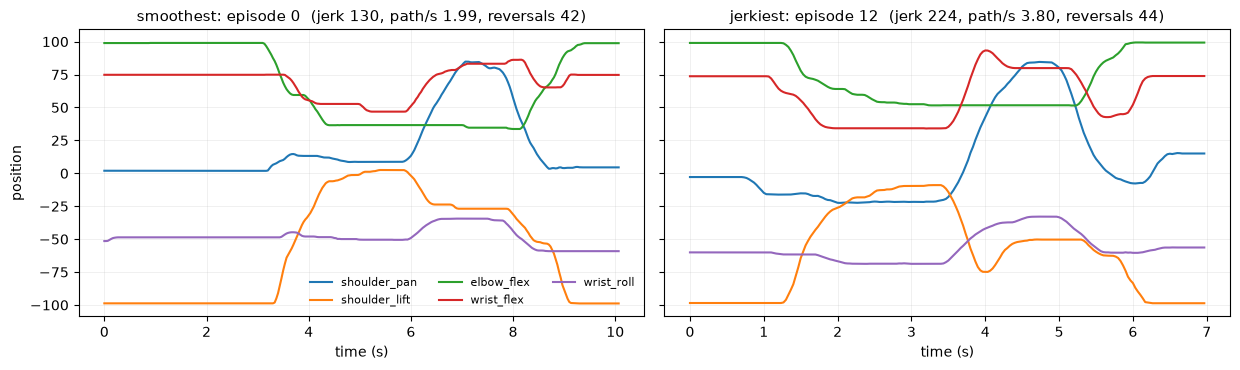

jerk spread across episodes: 1.7x  (min 130, max 224)

Honest reading: this dataset is fairly uniform in quality -- the jerk spread
is under 2x and there is no obvious outlier to throw away. That is good news
about `lerobot/svla_so101_pickplace`, and it is the point of running the check:
you now KNOW the data is clean rather than assuming it. On a community-collected
dataset this same ranking routinely surfaces episodes that are 5-10x jerkier
than the median, and those are worth watching before you train on them.


In [20]:
best, worst = int(q["jerk"].idxmin()), int(q["jerk"].idxmax())
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, e, lbl in zip(axes, [best, worst], ["smoothest", "jerkiest"]):
    ed = df[df.episode == e]
    for j in JOINTS:
        if j != "gripper":
            ax.plot(ed["t"], ed[f"state_{j}"], lw=1.5, label=j)
    ax.set_title(f"{lbl}: episode {e}  (jerk {q.loc[e,'jerk']:.0f}, "
                 f"path/s {q.loc[e,'path_per_s']:.2f}, reversals {q.loc[e,'reversals']})", fontsize=10.5)
    ax.set_xlabel("time (s)"); ax.grid(alpha=0.22, lw=0.6)
axes[0].set_ylabel("position"); axes[0].legend(frameon=False, ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

spread = q["jerk"].max() / q["jerk"].min()
print(f"jerk spread across episodes: {spread:.1f}x  (min {q['jerk'].min():.0f}, max {q['jerk'].max():.0f})")
print()
print("Honest reading: this dataset is fairly uniform in quality -- the jerk spread")
print("is under 2x and there is no obvious outlier to throw away. That is good news")
print("about `lerobot/svla_so101_pickplace`, and it is the point of running the check:")
print("you now KNOW the data is clean rather than assuming it. On a community-collected")
print("dataset this same ranking routinely surfaces episodes that are 5-10x jerkier")
print("than the median, and those are worth watching before you train on them.")

## 6. Normalisation statistics — the artifact for notebook 6

Section 1 showed the joints have wildly different ranges. Before training we
must put them on a common scale, otherwise the loss is dominated by whichever
joint has the largest numbers.

Two standard choices, and the distinction matters:

| | formula | maps to | good when |
|---|---|---|---|
| **mean/std** | $(x-\mu)/\sigma$ | mean 0, std 1 | roughly bell-shaped data |
| **min/max** | $2(x-\min)/(\max-\min)-1$ | $[-1, 1]$ | bounded signals, e.g. servo limits |

LeRobot defaults to **mean/std for states** and **min/max for actions**. The
reason is practical: actions are commanded servo positions with hard physical
limits, and squashing them to $[-1,1]$ pairs naturally with a `tanh` output head
that cannot command an impossible position. States are measurements, so
standardising them is the better conditioned choice.

One rule that is easy to get wrong and expensive to debug: **compute these
statistics on the training split only.** If you include the validation episodes,
information leaks and your validation loss lies to you.

In [21]:
# Train/val split BY EPISODE, never by frame -- frames within an episode are
# highly correlated, so a random frame split leaks the answer across the split.
all_eps = np.array(sorted(df["episode"].unique()))
rng = np.random.default_rng(42)
perm = rng.permutation(all_eps)
n_val = max(1, int(0.2 * len(all_eps)))
val_eps, train_eps = set(perm[:n_val].tolist()), set(perm[n_val:].tolist())
print(f"train: {len(train_eps)} episodes | val: {len(val_eps)} episodes -> {sorted(val_eps)}\n")

tr = df[df["episode"].isin(train_eps)]
action_cols = [f"action_{j}" for j in JOINTS]

stats = {
    "fps": FPS,
    "joints": JOINTS,
    "train_episodes": sorted(train_eps),
    "val_episodes": sorted(val_eps),
    "observation.state": {
        "mean": tr[state_cols].mean().tolist(),
        "std":  tr[state_cols].std().tolist(),
        "min":  tr[state_cols].min().tolist(),
        "max":  tr[state_cols].max().tolist(),
    },
    "action": {
        "mean": tr[action_cols].mean().tolist(),
        "std":  tr[action_cols].std().tolist(),
        "min":  tr[action_cols].min().tolist(),
        "max":  tr[action_cols].max().tolist(),
    },
    "measured_actuation_lag_frames": 4,          # from notebook 1, all 50/50 episodes
}

print(f"{'joint':16} {'state mean':>11} {'state std':>10} {'action min':>11} {'action max':>11}")
print("-" * 64)
for i, j in enumerate(JOINTS):
    print(f"{j:16} {stats['observation.state']['mean'][i]:>11.2f} {stats['observation.state']['std'][i]:>10.2f} "
          f"{stats['action']['min'][i]:>11.2f} {stats['action']['max'][i]:>11.2f}")

import os
os.makedirs("../artifacts", exist_ok=True)
with open("../artifacts/so101_stats.json", "w") as f:
    json.dump(stats, f, indent=2)
print("\nsaved -> artifacts/so101_stats.json   (notebook 6 loads this)")

train: 40 episodes | val: 10 episodes -> [5, 17, 20, 25, 27, 39, 45, 46, 47, 49]

joint             state mean  state std  action min  action max
----------------------------------------------------------------
shoulder_pan            8.47      44.06      -93.46       88.01
shoulder_lift         -54.96      36.64     -100.00        8.13
elbow_flex             66.44      27.39       12.97      100.00
wrist_flex             69.24      13.29       33.53       99.49
wrist_roll            -53.62      17.18      -92.48      -20.93
gripper                 8.30       8.51        0.00       33.00

saved -> artifacts/so101_stats.json   (notebook 6 loads this)


In [22]:
# Verify the normalisers round-trip. Always test a transform you will rely on.
def norm_state(x, st):  return (x - np.array(st["observation.state"]["mean"])) / np.array(st["observation.state"]["std"])
def norm_action(x, st):
    lo, hi = np.array(st["action"]["min"]), np.array(st["action"]["max"])
    return 2 * (x - lo) / (hi - lo) - 1
def denorm_action(y, st):
    lo, hi = np.array(st["action"]["min"]), np.array(st["action"]["max"])
    return (y + 1) / 2 * (hi - lo) + lo

Xs = tr[state_cols].values
Ya = tr[action_cols].values
Zs, Za = norm_state(Xs, stats), norm_action(Ya, stats)

print(f"normalised state : mean {Zs.mean():+.4f}  std {Zs.std():.4f}      (target: 0.0, 1.0)")
print(f"normalised action: min  {Za.min():+.4f}  max {Za.max():+.4f}      (target: -1.0, 1.0)")
print(f"round-trip error : {np.abs(denorm_action(Za, stats) - Ya).max():.3e}   (should be ~0)")
print()
val = df[df["episode"].isin(val_eps)]
Zv = norm_action(val[action_cols].values, stats)
print(f"validation actions after train-only normalisation: min {Zv.min():+.3f}  max {Zv.max():+.3f}")
print("Slightly outside [-1, 1] -- correct and expected. The val set contains poses")
print("the training episodes never reached. If it landed exactly in [-1,1] you would")
print("have leaked the validation data into your statistics.")

normalised state : mean +0.0000  std 0.9999      (target: 0.0, 1.0)
normalised action: min  -1.0000  max +1.0000      (target: -1.0, 1.0)
round-trip error : 1.421e-14   (should be ~0)

validation actions after train-only normalisation: min -1.008  max +1.026
Slightly outside [-1, 1] -- correct and expected. The val set contains poses
the training episodes never reached. If it landed exactly in [-1,1] you would
have leaked the validation data into your statistics.


That last check is a small thing that catches a real bug. If your validation
data fits your normaliser *perfectly*, you computed the statistics on everything
— and your validation metric is now optimistic. Seeing values slightly outside
the range is the signal that you did it right.

## 7. A 10-minute checklist for any robot dataset

Generalising what we just did. Run this on any LeRobot dataset on HuggingFace
before you commit to training on it.

| # | Check | Red flag |
|---|---|---|
| 1 | `meta/info.json` — fps, episode count, feature shapes and names | fps < 10 (too coarse to control), < 20 episodes |
| 2 | Episode length distribution | huge variance, or many very short episodes (aborted recordings) |
| 3 | Is `action` a position target? Run the lag sweep | no clear minimum — then the action is something else, find out what |
| 4 | Reward columns present? | absent is normal for teleop; it just means imitation learning |
| 5 | Per-joint ranges and stds | a joint that never moves (dead channel), or constant values |
| 6 | Velocity and jerk per episode | jerk outliers = hesitant demonstrations |
| 7 | Path inefficiency | >> 1 means wandering, corrections, retries |
| 8 | Cross-episode action disagreement | very high = strongly multimodal, plain BC will struggle |
| 9 | Camera keys and resolution | missing a wrist camera makes fine manipulation much harder |
| 10 | Train/val split **by episode**, stats on train only | splitting by frame inflates every metric you report |

Let us run the quick version against `lerobot/pusht` to show it generalises to a
dataset with a different robot, different fps, and a reward.

In [23]:
def quick_audit(repo, fps_expect=None):
    info = json.load(open(hf_hub_download(repo, "meta/info.json", repo_type="dataset")))
    d = pd.read_parquet(hf_hub_download(repo, "data/chunk-000/file-000.parquet", repo_type="dataset"))
    A_ = np.stack(d["action"].values).astype(np.float64)
    S_ = np.stack(d["observation.state"].values).astype(np.float64)
    L = d.groupby("episode_index").size()
    print(f"=== {repo}")
    print(f"  robot {info['robot_type']} | fps {info['fps']} | {info['total_episodes']} eps | {info['total_frames']} frames")
    print(f"  action dim {A_.shape[1]} | state dim {S_.shape[1]}")
    print(f"  episode length: min {L.min()} med {int(L.median())} max {L.max()}")
    print(f"  reward columns: {[c for c in d.columns if 'reward' in c or 'success' in c] or 'none (imitation only)'}")
    # check 3: is the action a position target?
    e0 = d[d.episode_index == 0].sort_values("frame_index")
    a0 = np.stack(e0['action'].values).astype(float); s0 = np.stack(e0['observation.state'].values).astype(float)
    errs = [np.abs(a0[:len(a0)-k] - s0[k:]).mean() for k in range(8)]
    k_best = int(np.argmin(errs))
    verdict = (f"position target, lag {k_best} frames ({k_best*1000/info['fps']:.0f} ms)" if 0 < k_best < 7
               else "NOT a simple position target -- investigate")
    print(f"  action semantics: {verdict}  [errors {np.round(errs,2).tolist()}]")
    print(f"  action range: [{A_.min():.1f}, {A_.max():.1f}] | state range: [{S_.min():.1f}, {S_.max():.1f}]")
    print()

quick_audit("lerobot/pusht")
quick_audit(REPO)

=== lerobot/pusht
  robot unknown | fps 10 | 206 eps | 25650 frames
  action dim 2 | state dim 2
  episode length: min 49 med 122 max 246
  reward columns: ['next.reward', 'next.success']
  action semantics: position target, lag 2 frames (200 ms)  [errors [12.12, 7.25, 2.55, 3.17, 7.93, 12.87, 17.79, 22.64]]
  action range: [12.0, 511.0] | state range: [13.5, 511.0]

=== lerobot/svla_so101_pickplace
  robot so100_follower | fps 30 | 50 eps | 11939 frames
  action dim 6 | state dim 6
  episode length: min 183 med 230 max 306
  reward columns: none (imitation only)
  action semantics: position target, lag 4 frames (133 ms)  [errors [2.11, 1.73, 1.34, 0.97, 0.77, 1.02, 1.36, 1.74]]
  action range: [-100.0, 100.0] | state range: [-98.9, 99.4]



Note the `pusht` result. Its action is *also* a position target with a lag, but
the numbers are different: 2-D actions in pixel coordinates at 10 fps. Same
concept, different robot — which is exactly the kind of transfer that makes the
audit worth memorising rather than re-deriving each time.

If a dataset's lag sweep has **no interior minimum**, stop and investigate. The
action is probably a velocity, a torque, or a delta — and if you train assuming
positions you will get a policy that does nothing sensible.

## 8. What you now have, and what is next

**Measured in this notebook:**

1. Velocities computed correctly with per-episode `groupby`, plus the discovery
   that **median velocity is 0 for five of six joints because of encoder
   quantisation** (34-83% of frames report an identical reading to the previous
   one). Use percentiles on this data, never medians.
2. **Tracking error is proportional to speed** (correlation 0.87) — the
   mechanical explanation of notebook 1's 133 ms lag. Notebook 5 reproduces it
   from a P-controller.
3. Task phases from the gripper channel: the grasp lands anywhere from **2.3 s
   to 5.6 s**, and **only 26 of 50 episodes contain a completed release** — a
   real gap in this dataset that its card does not mention, and one that will
   make a trained policy weaker at finishing than at starting.
4. **The dataset is NOT multimodal** — tested, not assumed. The action gap
   decays to (and below) the 33 ms baseline as poses converge. It is a
   stereotyped set: one operator, one motion, near-fixed object placement.
   This revises the prediction for notebook 6: plain BC should work, and the
   failure to expect is compounding error, not mode-averaging.
5. An episode quality ranking that found this dataset **uniformly clean** (jerk
   spread 1.7x, no outliers worth dropping).
6. `artifacts/so101_stats.json` — the normalisers notebook 6 trains with.

**The method that matters** is section 4's decay curve, not the specific answer.
A single summary number would have misled us by 4x; the curve settled it.

**The checklist** in section 7 generalises the whole notebook to any dataset on
the Hub.

---

### Next: notebook 3 — Physics from Scratch

We leave real data and build a simulator. Not because simulators are
intrinsically interesting, but because a simulator is an approximation of the
transition function $P$ — and notebook 1 established that $P$ is physics, which
you cannot write down or query in closed form.

You will implement a rigid-body integrator in pure `numpy`, watch your pendulum
gain energy and explode because you picked the obvious integration scheme, fix
it, and then check your trajectory against MuJoCo. Two completely different
computational routes to the same answer — the same style of sanity check you did
in notebook 1 of the RL course, when Monte Carlo value estimates converged to
the exact Bellman solution.

### Exercises

1. **Add the phase as an input.** Append "progress through episode" to the state
   vector and redo the nearest-neighbour match. How much does the action gap
   drop? This quantifies what a phase variable or action history buys you, and
   previews why real policies condition on more than the current frame.
2. **Gripper lag.** In notebook 1 the gripper had the lowest correlation (0.955
   vs ~0.999). Using the velocity columns and `frac exactly 0` (0.83 for the
   gripper!), work out whether that is because it moves fast, because it is
   nearly binary, or because it makes contact.
3. **Break the unimodality.** Subsample the dataset to simulate two operators:
   take episodes 0-24 as-is and episodes 25-49 with the `shoulder_pan` sign
   flipped. Re-run section 4. You should now see the plateau that genuine
   multimodality produces — which is what the diffusion policy in notebook 7 is
   built for.
4. **Find a genuinely multimodal dataset.** Search the Hub for an `so101`
   dataset with multiple contributors or varied object placement, run
   `quick_audit` plus the section 4 decay curve, and compare. If you find one
   that plateaus, use it in notebook 7 and you will see diffusion beat BC
   properly instead of marginally.